In [4]:
"""
Импорты и инициализация переменных внутри программы
Эта часть кода должна инициализироваться только один раз
"""

import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.special import j1
from lib import my_sources
mp.verbosity(0) # decrease amount of output

# Simulation parameters for MEEP
increase_resolution = 4 # by default, that should be 1. This parameter multiply min_resolution
X_cell_size = conf.cell_X # Width of simulation doesn't affect on lense.
Y_cell_size = conf.aperture # Aperture is 2 mm
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)]
angle = 0 # in degrees

# sources_obj = my_sources.KvectorSource(frequency=conf.inc_fcen, y = Y_cell_size, angle=angle)
# source = sources_obj.get_sources()

# src = mp.GaussianSource(frequency=conf.inc_fcen, fwidth=conf.inc_df)
# source = [mp.Source(src, component=mp.Ez, size=mp.Vector3(x=0, y=conf.cell_Y, z=0), center=conf.source_center)]

sources_obj = my_sources.DefSource(y=Y_cell_size)
source = sources_obj.get_sources()

# All parameters related to the definition of geometry
D_spot = Y_cell_size # actual size in micrometers equal D of lens
M = conf.pure_orders # the number of radial layers.
N_large_0order = 10
N = 4 # N must be even., 0 - 2 - 4 - 6 - 8 - 10
LIMIT_PRODUCT = 0.2 # Limitation 200 nm. Geometry can't be larger this size.

k = 2 * np.pi / conf.inc_wavelength # wave number
f = conf.f # focal length 50 mm
Q = 300 # curve detailing. It has almost no effect on the result
w = conf.w # 200 nm. The width of the gap between the curves

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)
"""
Здесь соберем все функции программы
"""
# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))

def zero_derivative (m):
    calculation = np.sqrt((4 * f * m * np.pi)/k)
    return calculation

def get_y_section(y0, curves):
    """
    Получить срез кривых плоскостью Y = y0.

    :param y0: Значение Y для среза.
    :param curves: Список массивов с координатами кривых [(x1, y1), (x2, y2), ...].
    :return: Координата (x) для пересечения.
    """
    sections = np.zeros(shape=4)
    n=0
    for curve in curves:
        x_vals, y_vals = curve
        x_first_center = 0
        for i in range(len(y_vals) - 1):           
            y1, y2 = y_vals[i], y_vals[i + 1]
            x1, x2 = x_vals[i], x_vals[i + 1]         
            if y1 <= y0 <= y2 or y2 <= y0 <= y1:
                # Линейная интерполяция для x
                x_interp = x1 + (y0 - y1) * (x2 - x1) / (y2 - y1)
                if x_first_center != x_interp: sections[n] = x_interp
                x_first_center = x_interp
                n = n + 1
                
    return sections

def get_x_section(L_center = True, amount_centers = 10):
    # Main loop for layers
    if L_center:
        x_sections = np.zeros((M,amount_centers,4))
    else: x_sections = np.zeros((M,N+1,4))
    
    for m in range(M):
        rt0 = 0 if m == 0 else rt[m - 1] + 0.1
        x = np.linspace(rt0, rt[m]-0.001, Q)
        # Compute y values by integration
        try:
            y = np.array([quad(fun, rt0, xi)[0] for xi in x])
        except Exception:
            y = 0
        
        yy = np.empty((amount_centers, 2), dtype=object)
        
        xt = x.copy()
        ip = np.argmin(y)
        y1 = y - y[ip]
        y11 = y1.copy()
        y2 = y11 - w
        
        if L_center:
            SECTION = w*amount_centers
            #Здесь мы собираем все кривые принадлежащие данному порядку
            for n in range(amount_centers):
                curves = []
                yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
                yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                     
                # Формируем кривые
                curves.append((xt, yy[n,0]))
                curves.append((xt, yy[n,1]))
                
                # Получаем срез при Y = SECTION
                x_sections[m, n] = get_y_section(SECTION, curves) 
            L_center = False
        
        else:
            SECTION = w*N
            for n in range(N):
                curves = []
                yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
                yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                     
                # Формируем кривые
                curves.append((xt, yy[n,0]))
                curves.append((xt, yy[n,1]))
                
                # Получаем срез при Y = SECTION
                x_sections[m, n] = get_y_section(SECTION, curves)
    
    return x_sections

def get_width_first_order(x_sections):
    result = []
    for n in range(N_large_0order): 
        if x_sections[0, n, 0] == 0:
            # Добавляем width_first_order
            width_first_order = x_sections[0, n, 1] * 2
            result.append(width_first_order)
            return result  # Завершаем функцию сразу после нахождения значения
        else:
            # Вычисляем ширину и добавляем её в список
            width = abs(x_sections[0, n, 0] - x_sections[0, n, 1])
            result.append(width)

def get_centers_first_order(x_sections):
    result = []
    for n in range(N_large_0order):
        if x_sections[0, n, 0] == 0:
            first_center = 0
            result.append(first_center)
            return result
        else:
            another_center = abs(x_sections[0, n, 0] + x_sections[0, n, 1]) /2
            result.append(another_center)
            
def get_width_other_order(x_sections,m):
    result = []
    for n in range(N):
        if (x_sections[m,n,0] != 0) and (x_sections[m,n,1] == 0) and (x_sections[m,n+1,0] == 0):
            third = abs(x_sections[m,n,2] - x_sections[m,n,3])
            result.append(third)
            return result  
        if x_sections[m,n,0] == 0 or x_sections[m,n,0] == 0:
            continue
        if x_sections[m,n,2] != 0:
            first = abs(x_sections[m,n,0] - x_sections[m,n,2])
            result.append(first)       
        if x_sections[m,n,3] != 0:
            second = abs(x_sections[m,n,1] - x_sections[m,n,3])
            result.append(second)
          
def get_center_of_other_order(x_sections, m):
    result = []
    for n in range(N):
        if (x_sections[m,n,0] != 0) and (x_sections[m,n,1] == 0) and (x_sections[m,n+1,0] == 0):
            center = zero_derivative(m)
            result.append(center)
            return result         
        
        if x_sections[m,n,0] == 0 or x_sections[m,n,0] == 0:
            continue        
        if x_sections[m,n,2] != 0:
            first = (x_sections[m,n,0] + x_sections[m,n,2])/2
            result.append(first)
        if x_sections[m,n,3] != 0:
            second = (x_sections[m,n,1] + x_sections[m,n,3])/2
            result.append(second) 

def test_match (list_of_centers):
    for i in range (len(list_of_centers)):
        for j in range(len(list_of_centers[i])):
            if list_of_centers[i][j] != list_of_centers[i][j]:
                ValueError("List elements do not match")
    
def flatten(lst):
    for item in lst:
        if isinstance(item, list):
            # Если элемент - это список, рекурсивно обрабатываем его
            yield from flatten(item)
        else:
            # Если элемент не список, возвращаем его
            yield item
def shift_y():
    if angle > 45:
        added_angle = 90 - angle
        add_shift_y = f*np.tan(np.radians(added_angle))
        shift_y = Y_cell_size + add_shift_y
    else:
        shift_y= (conf.source_center.x + f) * np.tan(np.radians(angle))
    return shift_y

def get_abscissa (D_spot, y, relation = "aperture"):
    """
    :param spot_size: область построения
    :param y: ордината
    :param toLimit: on/off relation to Airy disk
    :return: вектор нормированный либо на апертуру либо на площадь ограниченную дифракционным пределом
    """
    size_of_y = len(y)
    x_max = get_Airy_disk()
    x = np.zeros(size_of_y)
    if relation == "airy":
        x = np.linspace(-D_spot/2/x_max, D_spot/2/x_max, size_of_y)
    if relation == "aperture":
        x = np.linspace(-D_spot/2/Y_cell_size, D_spot/2/Y_cell_size, size_of_y)
    if relation == "abs":
        x = np.linspace(-D_spot/2, D_spot/2, size_of_y)
    return x

def get_Airy_disk ():
    x_max = 1.22 * conf.inc_wavelength * f / Y_cell_size
    return x_max

def plot_FF (I, D_spot, relation = "aperture"):
    
    x_lable = ""
    
    if relation == "airy":
        x_lable = "/ limit_airy"
    if relation == "aperture":
        x_lable = "/ aperture"
    
    frequents_array = np.linspace(conf.inc_wavelength-conf.inc_dwavelength/2, conf.inc_wavelength+conf.inc_dwavelength/2, conf.inc_nfreq)
    plt.figure(dpi=150)
    # Перебираем столбцы (второй индекс матрицы)
    if len(frequents_array) == 1:
            plt.semilogy(
            get_abscissa(D_spot, I, relation), I, label=f"Far field (wavelength {frequents_array[0]})"
        )
    else:
        for i in range(I.shape[1]):
            plt.semilogy(
                get_abscissa(D_spot, I, relation), I[:, i], label=f"Far field (wavelength {frequents_array[i]})"
            )
    
    plt.xlabel(f"x coordinate (spot {x_lable})")
    plt.ylabel(r"energy density of ff, |E$_z$|$^2$")
    plt.title(f"Intensity of CC lens. Incident {angle} degrees")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()     
    
def get_Izyx(sim, near2far_region,ff_res, size):
    """
    :param ff_res: коэффицент разрешения для дальнего поля. Обычно определяется как количесво пикселей деленное на реальный размер расчетного поля в микронах 
    :param size: mp.Vector3 с ненулевым значением по инетересующей координате
    :return Izyx: 1d вектор интенсивности всех компонентов напряженности для поля в рассчитаном сечении
    """
    # Calculating fields in the far zone on spot equals to spot_size. Focal Plane
    far_field = sim.get_farfields(
        near2far_region,
        ff_res,
        center=mp.Vector3(x=conf.flux_center[0] + f, y=shift_y()),
        size = size
    )
    Iz_far_field = abs(far_field["Ez"])**2
    Iy_far_field = abs(far_field["Ey"])**2
    Ix_far_field = abs(far_field["Ex"])**2
    Izyx = Iz_far_field+Iy_far_field+Ix_far_field
    
    # print(f"max Ez = {np.max(Iz_far_field)} , max Ey = {np.max(Iy_far_field)}, max Ex = {np.max(Ix_far_field)}")
   
    return Izyx

def get_psf(nfrec, I, D_spot):
    """
    :param nfrec(int): дискретность длин волн.
    :param I: массив с распределением интенсивностей
    :param D_spot: область на которой эти интенсивности определены
    :return: plots 
    """
    N = nfrec
    x = get_abscissa(D_spot, I[:,0], relation="aperture")
   
    # Создаём координатную сетку
    X, Y = np.meshgrid(x, x)
    # Преобразуем координаты в полярные
    R = np.sqrt(X**2 + Y**2)  # Радиальное расстояние
    # Визуализация 2D-распределения
    # Создаём фигуру с `N` подграфиками
    fig, axes = plt.subplots(1, N, figsize=(8 * N, 8))
    if N == 1:
        axes = [axes]  # Преобразуем в список для единообразной индексации
    
    print(f"shape of x is {x.shape} shape of I is {I[:,0].shape}")
    
    for i in range (N):
        # Интерполяция интенсивности
        interp_I_2d = interp1d(x, I[:,i], bounds_error=False, fill_value=0)
        
        I2d = interp_I_2d(R)
        # Нормализация интенсивности
        I2d_norm = (I2d - np.min(I2d)) / (np.max(I2d) - np.min(I2d))
        # Отображение 2D-распределения
        unit = 1  # Коэффициент
        extent = [x[0] * unit, x[-1] * unit, x[0] * unit, x[-1] * unit]

        im = axes[i].imshow(I2d_norm, cmap='viridis', extent=extent)
        axes[i].set_title(f"Interpolated 2D Intensity of {i+1}")
        axes[i].set_xlabel("Spot size / aperture")
        axes[i].set_ylabel("Spot size / aperture")
        fig.colorbar(im, ax=axes[i], label="Intensity")

    
    plt.tight_layout()
    plt.figtext(0.45, 0.95, "Resolution: {:} pixels".format(len(x)), 
                    ha="center", fontsize=20, color="blue")
    plt.show()
    
def calculate_Strehl (D_spot, I_simualed):
    """
    :param D_spot: based on the general area of calculation
    :param I_simualed: Intensity of CC lens
    :return: Strehl_ratio based on Intensity 
    """ 
    # Let's count Strehl ratio
    # Find spot size for I_Airy 
    X = get_abscissa(D_spot, I_simualed, relation = "abs")
    Y = X
    r = np.sqrt(X**2 + Y**2)
    
    # Интенсивность Эйри
    k = 2 * np.pi / conf.inc_wavelength
    I_Airy = 4 * (j1(k * r) / (k * r)) ** 2
    I_Airy[np.isnan(I_Airy)] = 1  # Исправляем деление на 0
    I_Airy /= np.sum(I_Airy) # Нормируем
    
    # Интенсивность мета-линзы
    I_simualed /=np.sum(I_simualed)
    
    # Calculation
    I_max = np.max(I_Airy)
    I_0 = np.max(I_simualed)
    Strehl_ratio = I_0/I_max
    
    return Strehl_ratio

def calculate_FOM (D_spot, nfecq, Ifocal, Idepth):
    """
    :param D_spot: field of calculation Strehl. Must match with spot of Far Fiel
    :param nfecq: amount of discrete wavelength
    :param Ifocal: Intensity in focal plane direction
    :param Idepth: Intensity in depth direction
    :return strehl_avarage: Avarage intensity of multiplied Strehl ratio for every wavelength
    """
    sum = 0
    for i in range(nfecq):
        strehl_focal = calculate_Strehl(D_spot, Ifocal[:,i])
        strehl_depth = calculate_Strehl(D_spot, Idepth[:,i])
        mult_strehl = strehl_focal*strehl_depth
        sum += mult_strehl
    strehl_avarage = sum/nfecq
    return strehl_avarage


In [5]:
geometry = []
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center.x),
))

sim = mp.Simulation(
    cell_size=conf.cell,
    boundary_layers= [mp.PML(thickness=conf.pml, direction=mp.X , side=mp.ALL)],
    geometry=geometry,
    sources=source,
    default_material=mp.Medium(index=1.0),
    resolution=conf.min_resolution * conf.coef_resolution,
    symmetries = [mp.Mirror(mp.Y)]
)

NearRegions = [mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=conf.spot_ff))]

# Adding a near2far area
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    conf.inc_df,      # ширина спектра
    conf.inc_nfreq, # дискретность частот
    NearRegions[0],
)

# plt.figure(figsize=(1, 100))
# sim.plot2D(
#     output_plane = mp.Volume(center=mp.Vector3(0, conf.cell_Y/4), size=mp.Vector3(conf.cell[0], conf.cell[1]/2))
# )
sim.run(until_after_sources=mp.stop_when_dft_decayed(maximum_run_time = conf.maximum_run_time))

far_x = [mp.Vector3(x = conf.f + conf.flux_center.x, y = shift_y(), z = 0)] 
far_field = sim.get_farfields(
    near2far_region,
    resolution = conf.resolution_base/D_spot, # resolution of the calculated field,
    center=far_x[0],
    size= mp.Vector3(D_spot, 0, 0),
)
Iz_basis = abs(far_field["Ez"])**2
Iy_basis = abs(far_field["Ey"])**2
Ix_basis = abs(far_field["Ex"])**2
I_basis = Iz_basis +Iy_basis+Ix_basis

sim.reset_meep()

<Axes: xlabel='X', ylabel='Y'>

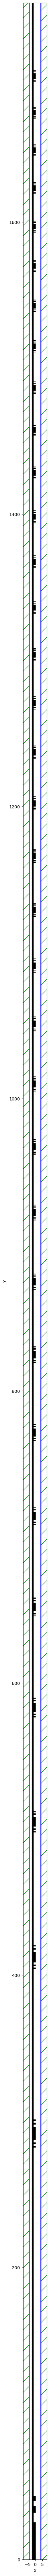

In [6]:
"""
Основной код программы
Эта часть кода должна вызваться итерационно оптимизатором.
Для начала сделаем ее функцией
"""

#### Start MEEP simulation
x_sections = get_x_section(L_center=False, amount_centers=N_large_0order) 
### End 1st PART
list_of_centers = []
list_of_widths = []
for m in range(1,M):
    other_center = get_center_of_other_order(x_sections, m)
    other_width = get_width_other_order(x_sections, m)
    list_of_centers.append(other_center)
    list_of_widths.append(other_width)
    
list_of_centers.insert(0,get_centers_first_order(x_sections))
list_of_widths.insert(0,get_width_first_order(x_sections))
# A test to check the basic parameters. The length of the widths at each radius (in each order should be equal to the length of the centers)
test_match(list_of_centers)
# Getting all the items from the nested lists
flat_centers = list(flatten(list_of_centers))
flat_widths = list(flatten(list_of_widths))
# Let's put it all into geometry
for i in range(len(flat_centers)):
    if flat_widths[i] < LIMIT_PRODUCT:
        continue
    else:
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
            center=mp.Vector3(x=conf.at_center.x, y=flat_centers[i], z=0)
        ))
        
### End 3d PART
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=source,
    k_point = mp.Vector3(0,0,0),
    # k_point=sources_obj.get_k_vector(),
    resolution=conf.min_resolution * increase_resolution,
    symmetries = [mp.Mirror(mp.Y)]
)
# Adding a near2far area
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    conf.inc_df,      # ширина спектра
    conf.inc_nfreq, # дискретность частот
    mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=D_spot)),
)
plt.figure(figsize=(1, 150))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,cell[1]/4,0), size=mp.Vector3(cell[0], cell[1]/2,0))
)

In [7]:
### End 4th PART
# Running the simulation
sim.run(until_after_sources=mp.stop_when_dft_decayed(maximum_run_time = conf.maximum_run_time))
# conf.run_end_time(sim)
### End 5th PART
ff_res = conf.resolution_base/D_spot # resolution of the calculated field
Izyx_fp = get_Izyx(sim, near2far_region,ff_res, mp.Vector3(0, D_spot, 0))
# End 6th PART
# Calculating fields in the far zone. Optical Axis
Izyx_oa = get_Izyx(sim, near2far_region,ff_res, mp.Vector3(D_spot, 0, 0))

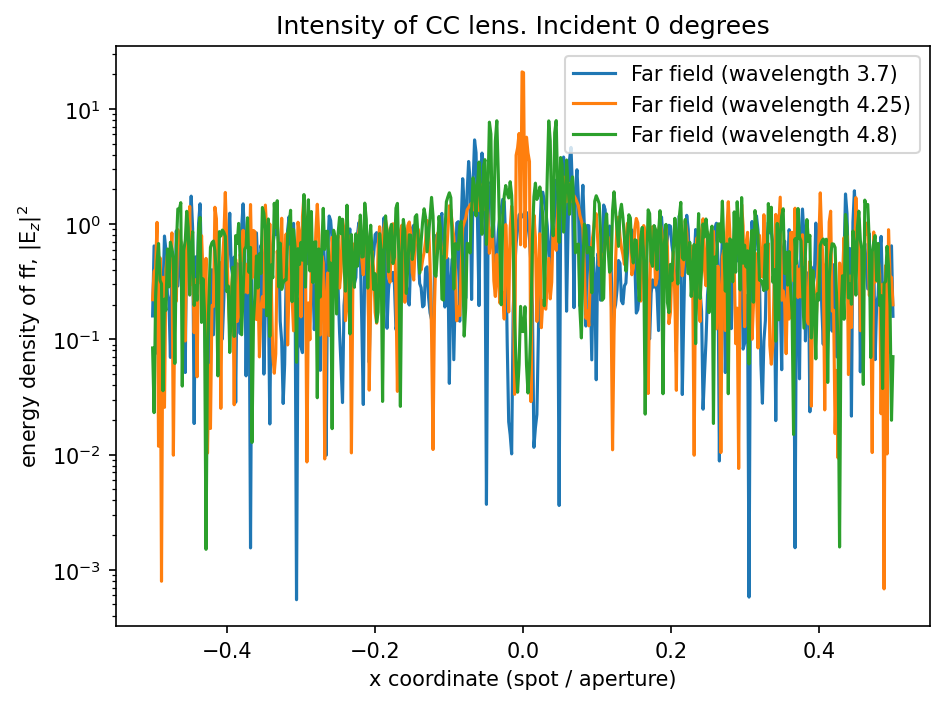

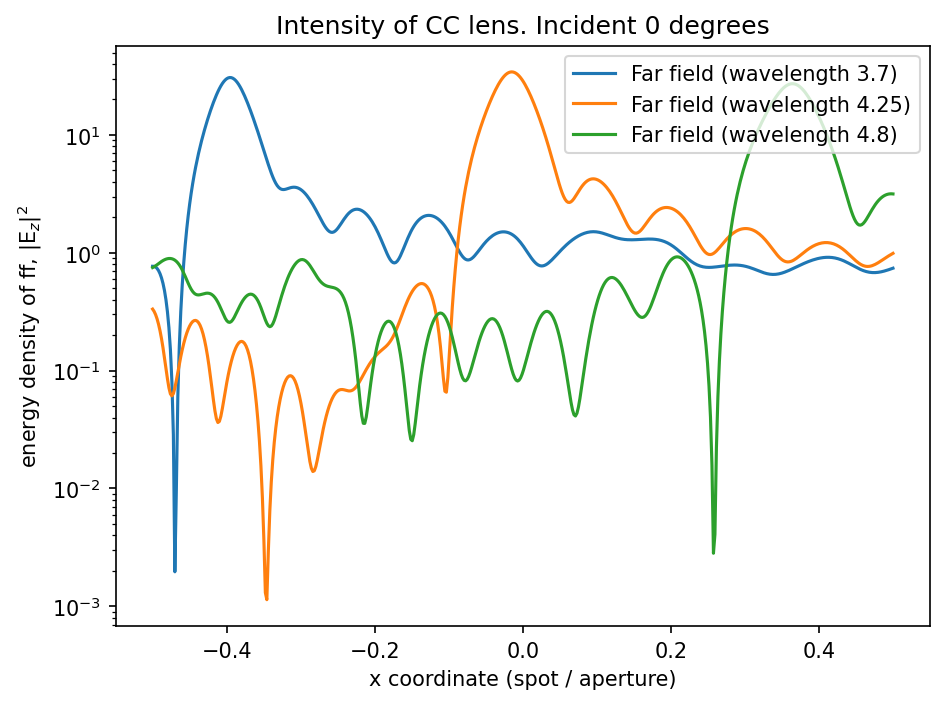

shape of x is (500,) shape of I is (500,)


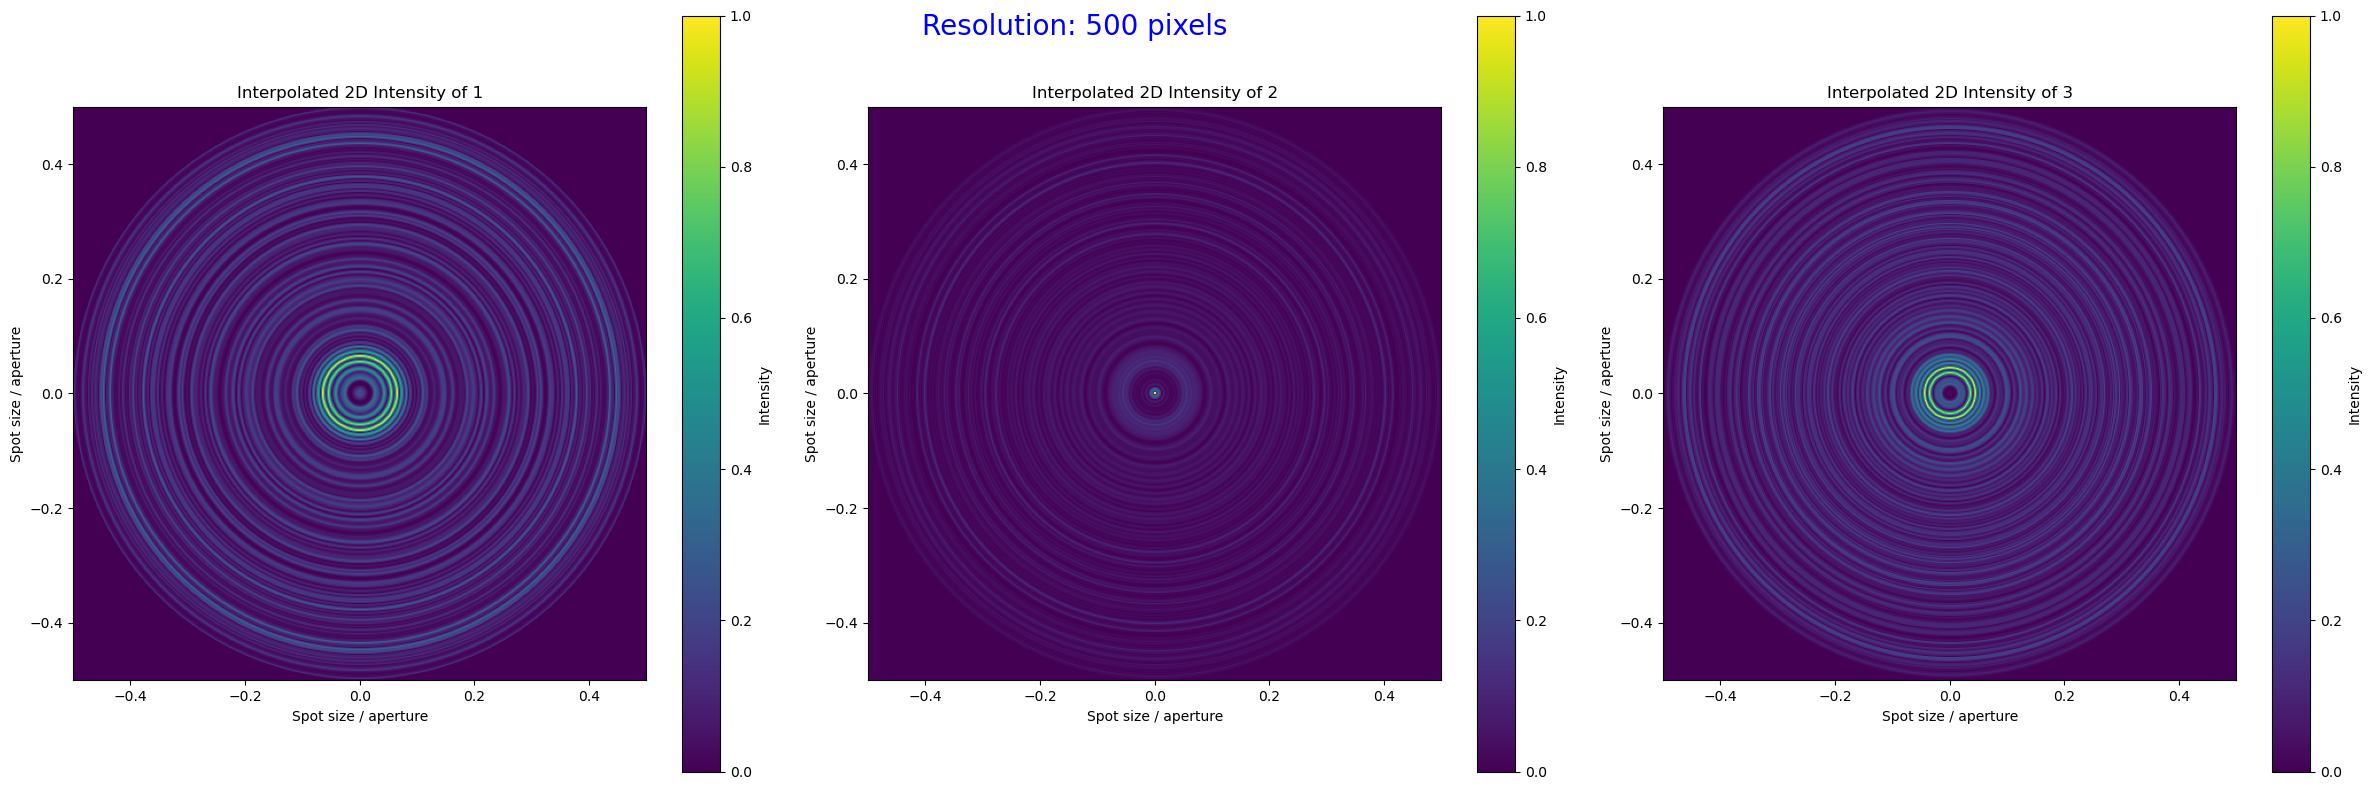

In [8]:
### End 7th PART
plot_FF(Izyx_fp/I_basis, D_spot)
plot_FF(Izyx_oa/I_basis, D_spot)
get_psf(conf.inc_nfreq, Izyx_fp, D_spot)
FOM = calculate_FOM(D_spot, conf.inc_nfreq, Izyx_fp, Izyx_oa)
### End 8th PART
#### End MEEP simulation

In [9]:
FOM

0.003740525792546117